# Forecast comparison against the REE benchmark

### Out-of-sample comparison of the ML model, a weekly baseline and REE's D+1 forecast

This notebook evaluates the final machine-learning forecast against the
official REE day-ahead demand forecast (ESIOS indicator 1775).

All forecasts are compared over exactly the same out-of-sample hours
from January 2025 through August 2026.

The April 2025 Iberian blackout is retained in the all-events results
and separately excluded when reporting normal-operation performance.

In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energy_forecasting.evaluation import regression_metrics

In [17]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"

forecast_ml = pd.read_csv(
    processed_dir / "forecast_boost.csv",
    index_col="datetime_utc",
    parse_dates=["datetime_utc"],
)

ree_forecast = pd.read_csv(
    processed_dir / "forecast_demand_hourly.csv",
    index_col="datetime_utc",
    parse_dates=["datetime_utc"],
)

real_demand = pd.read_csv(
    processed_dir / "real_demand_hourly.csv",
    index_col="datetime_utc",
    parse_dates=["datetime_utc"],
)

In [18]:
for frame in [
    forecast_ml,
    ree_forecast,
    real_demand,
]:
    frame.index = pd.to_datetime(
        frame.index,
        utc=True,
    )

forecast_ml["datetime_local"] = pd.to_datetime(
    forecast_ml["datetime_local"],
    utc=True,
).dt.tz_convert("Europe/Madrid")

## 1. Comparable forecast sample

The ML test set defines the evaluation sample. REE and weekly-baseline
forecasts are aligned to these exact timestamps so that all reported
metrics are directly comparable.

In [19]:
comparison = forecast_ml[
    [
        "datetime_local",
        "demand_MW",
        "forecast_ml",
        "is_blackout",
    ]
].copy()

comparison["forecast_ree"] = (
    ree_forecast["value"]
    .reindex(comparison.index)
)

comparison["forecast_lag168"] = (
    real_demand["value"]
    .shift(168)
    .reindex(comparison.index)
)

In [20]:
assert comparison.index.is_unique
assert comparison.isna().sum().sum() == 0
assert comparison["is_blackout"].sum() == 19

print("Rows:", len(comparison))
print("Start:", comparison["datetime_local"].min())
print("End:", comparison["datetime_local"].max())

comparison.head()

Rows: 14591
Start: 2025-01-01 00:00:00+01:00
End: 2026-08-31 23:00:00+02:00


,datetime_local,demand_MW,forecast_ml,is_blackout,forecast_ree,forecast_lag168
datetime_utc,,,,,,
2024-12-31 23:00:00+00:00,2025-01-01 00:00:00+01:00,22924.000000,20971.785247,False,23530.8,21646.500000
2025-01-01 00:00:00+00:00,2025-01-01 01:00:00+01:00,22185.916667,21096.561097,False,22670.3,20737.250000
2025-01-01 01:00:00+00:00,2025-01-01 02:00:00+01:00,20952.833333,19989.772718,False,21420.5,19471.416667
2025-01-01 02:00:00+00:00,2025-01-01 03:00:00+01:00,19774.750000,19386.697825,False,20285.0,18462.083333
2025-01-01 03:00:00+00:00,2025-01-01 04:00:00+01:00,18973.583333,19084.245030,False,19470.5,17824.333333


## 2. Out-of-sample forecast accuracy

Performance is reported both over the complete test sample and under
normal operating conditions, excluding only the explicitly flagged
blackout interval.

In [21]:
def evaluate_forecasts(data):
    records = []

    for model, column in {
        "Weekly baseline": "forecast_lag168",
        "ML forecast": "forecast_ml",
        "REE D+1 forecast": "forecast_ree",
    }.items():
        metrics = regression_metrics(
            data["demand_MW"],
            data[column],
        )

        records.append({
            "model": model,
            **metrics,
        })

    return (
        pd.DataFrame(records)
        .set_index("model")
    )

In [22]:
metrics_all = evaluate_forecasts(comparison)

normal_operation = comparison[
    ~comparison["is_blackout"]
]

metrics_normal = evaluate_forecasts(
    normal_operation
)

metrics_all

,MAE,RMSE,MAPE
model,,,
Weekly baseline,1387.341735,2129.756610,0.057321
ML forecast,779.072882,1196.013793,0.035639
REE D+1 forecast,474.462365,854.670385,0.025696


In [23]:
metrics_normal

,MAE,RMSE,MAPE
model,,,
Weekly baseline,1372.491805,2067.960837,0.048576
ML forecast,762.924150,1075.196596,0.026657
REE D+1 forecast,456.752608,642.784278,0.016151


In [24]:
accuracy_summary = pd.DataFrame({
    "MAE all-events (MW)": metrics_all["MAE"],
    "MAE normal-operation (MW)": metrics_normal["MAE"],
    "MAPE normal-operation (%)": (
        100 * metrics_normal["MAPE"]
    ),
})

accuracy_summary.round(2)

,MAE all-events (MW),MAE normal-operation (MW),MAPE normal-operation (%)
model,,,
Weekly baseline,1387.34,1372.49,4.86
ML forecast,779.07,762.92,2.67
REE D+1 forecast,474.46,456.75,1.62


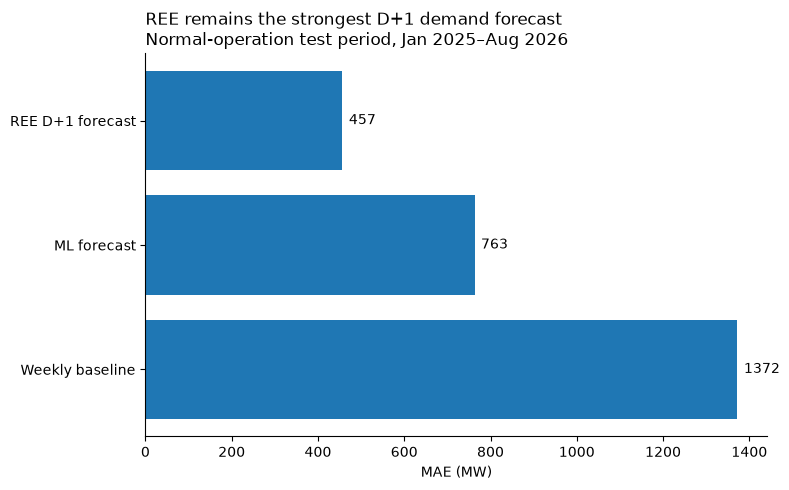

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

mae_normal = (
    metrics_normal["MAE"]
    .sort_values(ascending=False)
)

bars = ax.barh(
    mae_normal.index,
    mae_normal.values,
)

for bar, value in zip(
    bars,
    mae_normal.values,
):
    ax.text(
        value + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.0f}",
        va="center",
    )

ax.set_xlabel("MAE (MW)")
ax.set_title(
    "REE remains the strongest D+1 demand forecast\n"
    "Normal-operation test period, Jan 2025–Aug 2026",
    loc="left",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## 3. Performance stability over time

Year-level results show whether the relative performance of the
forecasts is stable across the two out-of-sample periods.

In [26]:
normal_operation = normal_operation.copy()

normal_operation["year"] = (
    normal_operation["datetime_local"].dt.year
)

yearly_records = []

for year, data_year in normal_operation.groupby("year"):

    year_metrics = evaluate_forecasts(data_year)

    for model, row in year_metrics.iterrows():
        yearly_records.append({
            "year": year,
            "model": model,
            "MAE": row["MAE"],
            "MAPE": row["MAPE"],
        })

yearly_metrics = pd.DataFrame(yearly_records)

yearly_metrics

,year,model,MAE,MAPE
0,2025,Weekly baseline,1449.905512,0.053028
1,2025,ML forecast,770.184569,0.028332
2,2025,REE D+1 forecast,465.393450,0.017007
3,2026,Weekly baseline,1256.444263,0.041901
4,2026,ML forecast,752.040371,0.024147
5,2026,REE D+1 forecast,443.799494,0.014869


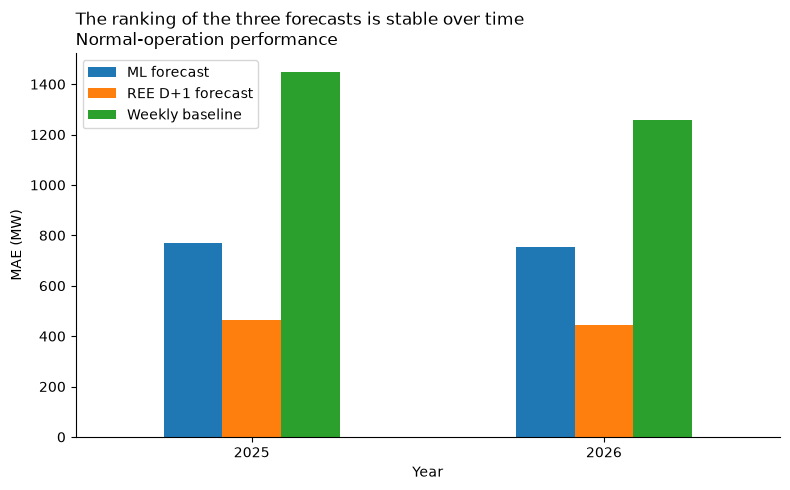

In [27]:
yearly_mae = (
    yearly_metrics
    .pivot(
        index="year",
        columns="model",
        values="MAE",
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

yearly_mae.plot(
    kind="bar",
    ax=ax,
)

ax.set_xlabel("Year")
ax.set_ylabel("MAE (MW)")
ax.set_title(
    "The ranking of the three forecasts is stable over time\n"
    "Normal-operation performance",
    loc="left",
)

ax.legend(title=None)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Example forecast week

A short normal-operation window illustrates how the three forecasts
track the intraday demand profile beyond aggregate error metrics.

In [28]:
plot_start = pd.Timestamp(
    "2026-07-06 00:00",
    tz="Europe/Madrid",
)

plot_end = pd.Timestamp(
    "2026-07-13 00:00",
    tz="Europe/Madrid",
)

sample = comparison[
    (comparison["datetime_local"] >= plot_start)
    & (comparison["datetime_local"] < plot_end)
]

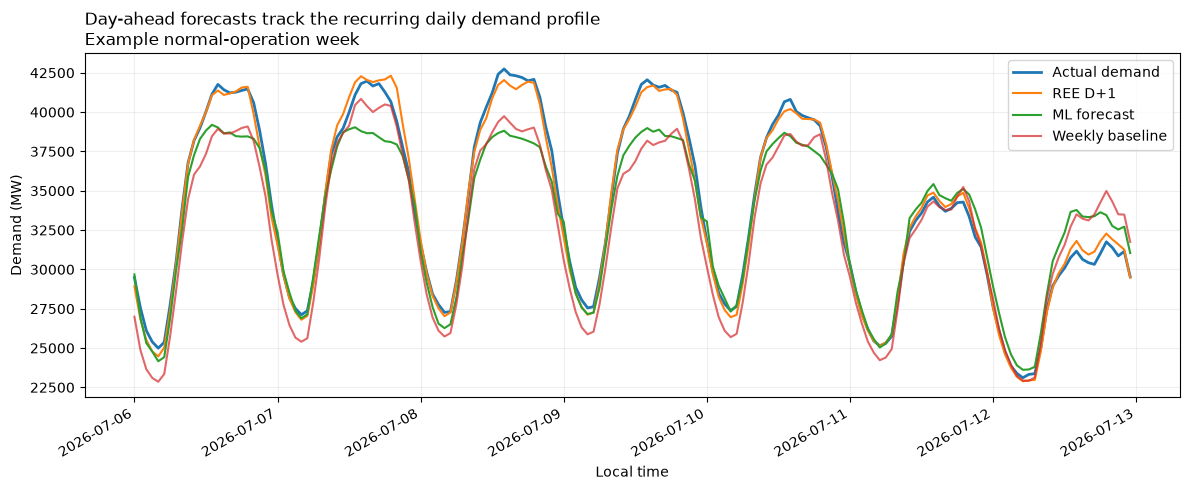

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    sample["datetime_local"],
    sample["demand_MW"],
    label="Actual demand",
    linewidth=2,
)

ax.plot(
    sample["datetime_local"],
    sample["forecast_ree"],
    label="REE D+1",
)

ax.plot(
    sample["datetime_local"],
    sample["forecast_ml"],
    label="ML forecast",
)

ax.plot(
    sample["datetime_local"],
    sample["forecast_lag168"],
    label="Weekly baseline",
    alpha=0.7,
)

ax.set_ylabel("Demand (MW)")
ax.set_xlabel("Local time")

ax.set_title(
    "Day-ahead forecasts track the recurring daily demand profile\n"
    "Example normal-operation week",
    loc="left",
)

ax.legend()
ax.grid(alpha=0.2)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 5. Comparison artifact

The aligned forecast dataset is saved for the subsequent procurement
backtest.

In [30]:
comparison.to_csv(
    processed_dir / "all_demands.csv",
    index=True,
)

comparison.head()

,datetime_local,demand_MW,forecast_ml,is_blackout,forecast_ree,forecast_lag168
datetime_utc,,,,,,
2024-12-31 23:00:00+00:00,2025-01-01 00:00:00+01:00,22924.000000,20971.785247,False,23530.8,21646.500000
2025-01-01 00:00:00+00:00,2025-01-01 01:00:00+01:00,22185.916667,21096.561097,False,22670.3,20737.250000
2025-01-01 01:00:00+00:00,2025-01-01 02:00:00+01:00,20952.833333,19989.772718,False,21420.5,19471.416667
2025-01-01 02:00:00+00:00,2025-01-01 03:00:00+01:00,19774.750000,19386.697825,False,20285.0,18462.083333
2025-01-01 03:00:00+00:00,2025-01-01 04:00:00+01:00,18973.583333,19084.245030,False,19470.5,17824.333333
